# 02 — Forbes Billionaires (2021)

Source: https://www.kaggle.com/datasets/roysouravcu/forbes-billionaires-of-2021
Cleans Chilean billionaires, converts `NetWorth` to CLP (759.1 CLP/USD), and saves `data/processed/forbes_2021_clp.{csv,parquet}`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import os

from utils import load_root
ROOT = load_root()

from source.cleaning import clean_networth_column, convert_currency
from source import figures as figplot

%load_ext autoreload
%autoreload 2

[utils] Project root loaded successfully: /home/choroy/Documents/doctorado/S4/ENECO894/problem-set


In [2]:
FIGURES_OUT = ROOT / 'figures'
DATA_OUT = ROOT / 'data/processed/'

### FORBES Billionaries (2021)
source = https://www.kaggle.com/datasets/roysouravcu/forbes-billionaires-of-2021

In [3]:
forbes_df = pd.read_csv(os.path.join(ROOT, 'data/Forbes/forbes-2021-kaggle.csv'))
ch_forbes_df = forbes_df[forbes_df['Country'] == 'Chile']
ch_forbes_df.sample()

,Name,NetWorth,Country,Source,Rank,Age,Industry
73,Iris Fontbona & family,$23.3 B,Chile,mining,74,78.0,Metals & Mining


In [4]:
ch_forbes_df['networth-clean'] = clean_networth_column(ch_forbes_df['NetWorth'])
ch_forbes_df['networth-clp'] = convert_currency(ch_forbes_df['networth-clean'], rate=759.1, to='clp')
ch_forbes_df = ch_forbes_df.sort_values('networth-clp', ascending=True)

saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set/figures/billionaires.pdf


PosixPath('/home/choroy/Documents/doctorado/S4/ENECO894/problem-set/figures/billionaires.pdf')

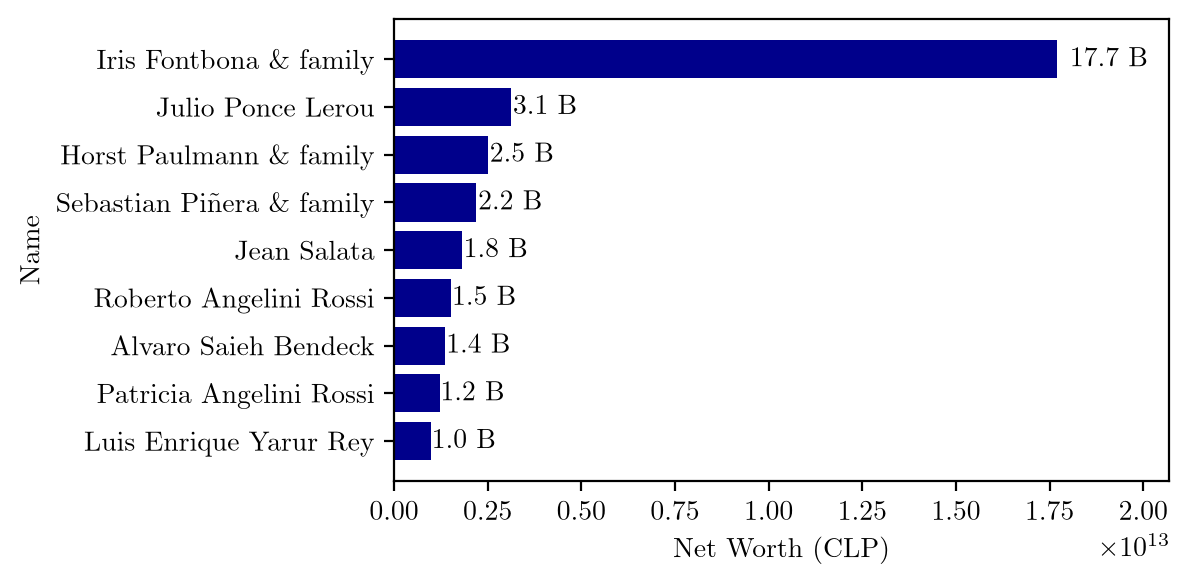

In [5]:
fig, ax = plt.subplots(1, 1,figsize=(5, 3),dpi=200)
fig, ax = figplot.plot_bar_billionaires(ch_forbes_df, fig=fig, ax=ax)
figplot.save_fig(FIGURES_OUT / 'billionaires.pdf', fig, dpi=300)

In [6]:
# Forbes Chile 2021 in CLP — needed for Vermeulen ii)
forbes_out = ch_forbes_df[['Name', 'Country', 'NetWorth', 'networth-clean', 'networth-clp']].copy()
forbes_out.to_parquet(DATA_OUT / 'forbes_2021_clp.parquet', index=False)
forbes_out.to_csv(DATA_OUT / 'forbes_2021_clp.csv', index=False)
print(f"saved Forbes to {DATA_OUT / 'forbes_2021_clp.parquet'} — shape {forbes_out.shape}")


saved Forbes to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set/data/processed/forbes_2021_clp.parquet — shape (9, 5)
